# Crop Disease Detection (EfficientNetV2B0) – Colab version

**Before running:** `Runtime → Change runtime type → T4 GPU`, then run the cells top to bottom.

In [1]:
# 1. Check GPU + download dataset from Kaggle (public dataset, no API key needed)
!nvidia-smi
import kagglehub
dataset_path = kagglehub.dataset_download('snikhilrao/crop-disease-detection-dataset')
print("Dataset downloaded to:", dataset_path)

Fri Nov  6 16:57:38 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

100%|██████████| 1.01G/1.01G [00:11<00:00, 96.6MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/snikhilrao/crop-disease-detection-dataset/versions/1


In [2]:
# 2. Imports
import os
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
# 3. Locate the Train / Val / Test folders automatically
#    (the folder layout inside the Kaggle download differs from /kaggle/input)
def find_splits(root):
    for dirpath, dirnames, _ in os.walk(root):
        lower = {d.lower(): d for d in dirnames}
        val_key = next((k for k in ('val', 'valid', 'validation') if k in lower), None)
        if 'train' in lower and val_key and 'test' in lower:
            return (os.path.join(dirpath, lower['train']),
                    os.path.join(dirpath, lower[val_key]),
                    os.path.join(dirpath, lower['test']))
    raise FileNotFoundError(f"Could not find Train/Val/Test folders under {root}")

train_dir, val_dir, test_dir = find_splits(dataset_path)
print("Train:", train_dir)
print("Val  :", val_dir)
print("Test :", test_dir)
print("Number of train classes:", len(os.listdir(train_dir)))

Train: /root/.cache/kagglehub/datasets/snikhilrao/crop-disease-detection-dataset/versions/1/Plant Village Dataset/Train
Val  : /root/.cache/kagglehub/datasets/snikhilrao/crop-disease-detection-dataset/versions/1/Plant Village Dataset/Val
Test : /root/.cache/kagglehub/datasets/snikhilrao/crop-disease-detection-dataset/versions/1/Plant Village Dataset/Test
Number of train classes: 29


In [4]:
# 4. Data pipeline
IMG_SIZE = 192
BATCH_SIZE = 32          # 8 was far too small for a GPU
SEED = 42
AUTOTUNE = tf.data.AUTOTUNE

data_augmentation = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

def prepare_dataset(directory, augment=False, shuffle=False):
    ds = keras.utils.image_dataset_from_directory(
        directory,
        seed=SEED,
        image_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE,
        label_mode='categorical',
        shuffle=shuffle,          # shuffle only training data
    )
    class_names = ds.class_names
    if augment:
        # augmentation is applied fresh every epoch (not cached)
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                    num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE), class_names

train_ds, class_names = prepare_dataset(train_dir, augment=True, shuffle=True)
val_ds, _  = prepare_dataset(val_dir)
test_ds, _ = prepare_dataset(test_dir)   # shuffle=False so labels line up with predictions

NUM_CLASSES = len(class_names)
INV_CLASS_MAP = {i: name for i, name in enumerate(class_names)}
print("Classes:", INV_CLASS_MAP)

Found 53693 files belonging to 29 classes.
Found 12067 files belonging to 29 classes.
Found 1358 files belonging to 29 classes.
Classes: {0: 'Apple - Apple Scab', 1: 'Apple - Black Rot', 2: 'Apple - Cedar Apple Rust', 3: 'Apple - Healthy', 4: 'Bell Pepper - Bacterial Spot', 5: 'Bell Pepper - Healthy', 6: 'Cherry - Healthy', 7: 'Cherry - Powdery Mildew', 8: 'Corn (Maize) - Cercospora Leaf Spot', 9: 'Corn (Maize) - Common Rust', 10: 'Corn (Maize) - Healthy', 11: 'Corn (Maize) - Northern Leaf Blight', 12: 'Grape - Black Rot', 13: 'Grape - Esca (Black Measles)', 14: 'Grape - Healthy', 15: 'Grape - Leaf Blight', 16: 'Peach - Bacterial Spot', 17: 'Peach - Healthy', 18: 'Potato - Early Blight', 19: 'Potato - Healthy', 20: 'Potato - Late Blight', 21: 'Strawberry - Healthy', 22: 'Strawberry - Leaf Scorch', 23: 'Tomato - Bacterial Spot', 24: 'Tomato - Early Blight', 25: 'Tomato - Healthy', 26: 'Tomato - Late Blight', 27: 'Tomato - Septoria Leaf Spot', 28: 'Tomato - Yellow Leaf Curl Virus'}


In [5]:
# 5. Model (EfficientNetV2B0 transfer learning)
from tensorflow.keras import mixed_precision
from tensorflow.keras.applications import EfficientNetV2B0

mixed_precision.set_global_policy('mixed_float16')   # T4 GPU supports this

def build_model(num_classes, img_size=IMG_SIZE):
    base = EfficientNetV2B0(include_top=False,
                            input_shape=(img_size, img_size, 3),
                            weights='imagenet')
    base.trainable = False   # Phase 1: backbone frozen

    inputs = keras.Input(shape=(img_size, img_size, 3))
    x = base(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation='softmax', dtype='float32')(x)  # float32 output for mixed precision
    return keras.Model(inputs, outputs), base

model, base_model = build_model(NUM_CLASSES)
model.compile(optimizer=keras.optimizers.Adam(1e-4),
              loss='categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 192, 192, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-b0 (Functional)  │ (None, 6, 6, 1280)     │     5,919,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 29)             │        37,149 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,956,461 (22.72 MB)

 Trainable params: 37,149 (145.11 KB)

 Non-trainable params: 5,919,312 (22.58 MB)

In [6]:
# 6. Two-phase training
EPOCHS_PHASE1 = 2
EPOCHS_PHASE2 = 6
CHECKPOINT_PATH = 'plant_effnetv2b0_best.keras'

def make_callbacks():
    return [
        keras.callbacks.ModelCheckpoint(CHECKPOINT_PATH, save_best_only=True,
                                        monitor='val_accuracy', mode='max'),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                          patience=2, min_lr=1e-7),
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=3,
                                      restore_best_weights=True),
    ]

# ---- Phase 1: train only the classifier head ----
print("---- Phase 1: training top layers only ----")
history1 = model.fit(train_ds, validation_data=val_ds,
                     epochs=EPOCHS_PHASE1, callbacks=make_callbacks())

# ---- Phase 2: fine-tune the last 30 backbone layers (BatchNorm stays frozen) ----
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

print("---- Phase 2: fine-tuning backbone ----")
history2 = model.fit(train_ds, validation_data=val_ds,
                     epochs=EPOCHS_PHASE2, callbacks=make_callbacks())

---- Phase 1: training top layers only ----
Epoch 1/2
1678/1678 ━━━━━━━━━━━━━━━━━━━━ 495s 268ms/step - accuracy: 0.5530 - loss: 1.8891 - val_accuracy: 0.8131 - val_loss: 0.9712 - learning_rate: 1.0000e-04
Epoch 2/2
1678/1678 ━━━━━━━━━━━━━━━━━━━━ 382s 227ms/step - accuracy: 0.8144 - loss: 0.8695 - val_accuracy: 0.8791 - val_loss: 0.5806 - learning_rate: 1.0000e-04
---- Phase 2: fine-tuning backbone ----
Epoch 1/6
1678/1678 ━━━━━━━━━━━━━━━━━━━━ 472s 256ms/step - accuracy: 0.8691 - loss: 0.4464 - val_accuracy: 0.9276 - val_loss: 0.2461 - learning_rate: 1.0000e-05
Epoch 2/6
1678/1678 ━━━━━━━━━━━━━━━━━━━━ 382s 228ms/step - accuracy: 0.8976 - loss: 0.3324 - val_accuracy: 0.9419 - val_loss: 0.1954 - learning_rate: 1.0000e-05
Epoch 3/6
1678/1678 ━━━━━━━━━━━━━━━━━━━━ 394s 235ms/step - accuracy: 0.9128 - loss: 0.2785 - val_accuracy: 0.9502 - val_loss: 0.1652 - learning_rate: 1.0000e-05
Epoch 4/6
1678/1678 ━━━━━━━━━━━━━━━━━━━━ 400s 238ms/step - accuracy: 0.9235 - loss: 0.2426 - val_accuracy: 0.95

In [7]:
# 7. Evaluate on the test set
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test Accuracy: {test_acc*100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

43/43 ━━━━━━━━━━━━━━━━━━━━ 17s 409ms/step - accuracy: 0.9610 - loss: 0.1132
Test Accuracy: 96.10%
Test Loss: 0.1132


In [8]:
# 8. Sample predictions from the first test batch
for images, labels in test_ds.take(1):
    preds = model.predict(images, verbose=0)
    predicted_class = tf.argmax(preds, axis=1).numpy()
    true_class = tf.argmax(labels, axis=1).numpy()
    for i in range(len(images)):
        print(f"True: {INV_CLASS_MAP[int(true_class[i])]} | Predicted: {INV_CLASS_MAP[int(predicted_class[i])]}")

True: Apple - Apple Scab | Predicted: Apple - Apple Scab
True: Apple - Apple Scab | Predicted: Apple - Apple Scab
True: Apple - Apple Scab | Predicted: Apple - Apple Scab
True: Apple - Apple Scab | Predicted: Apple - Apple Scab
True: Apple - Apple Scab | Predicted: Apple - Apple Scab
True: Apple - Apple Scab | Predicted: Apple - Apple Scab
True: Apple - Apple Scab | Predicted: Apple - Apple Scab
True: Apple - Apple Scab | Predicted: Apple - Apple Scab
True: Apple - Apple Scab | Predicted: Apple - Apple Scab
True: Apple - Apple Scab | Predicted: Apple - Apple Scab
True: Apple - Apple Scab | Predicted: Apple - Apple Scab
True: Apple - Apple Scab | Predicted: Apple - Apple Scab
True: Apple - Apple Scab | Predicted: Apple - Apple Scab
True: Apple - Apple Scab | Predicted: Apple - Apple Scab
True: Apple - Apple Scab | Predicted: Apple - Apple Scab
True: Apple - Apple Scab | Predicted: Apple - Apple Scab
True: Apple - Apple Scab | Predicted: Apple - Apple Scab
True: Apple - Apple Scab | Pred

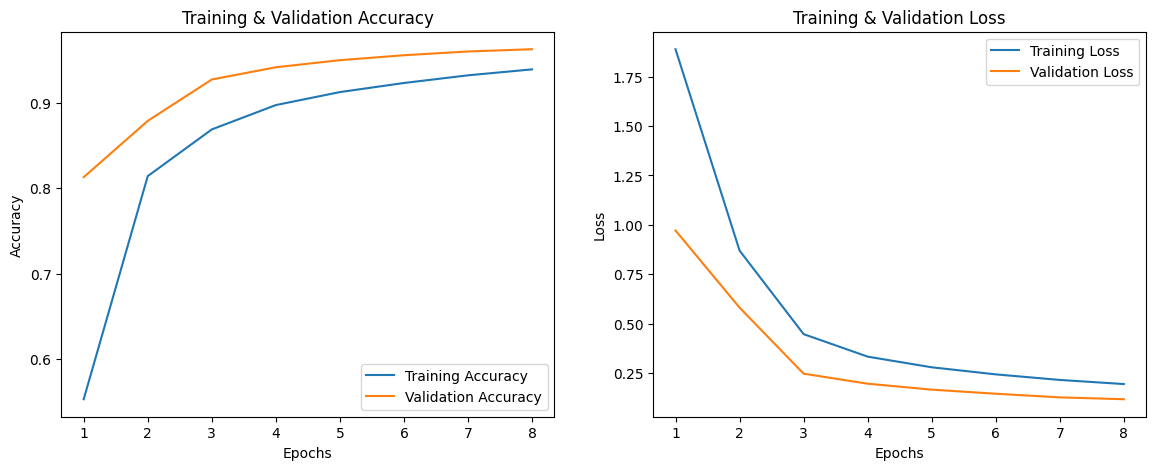

In [9]:
# 9. Training curves
acc = history1.history['accuracy'] + history2.history['accuracy']
val_acc = history1.history['val_accuracy'] + history2.history['val_accuracy']
loss = history1.history['loss'] + history2.history['loss']
val_loss = history1.history['val_loss'] + history2.history['val_loss']
epochs = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs, acc, label='Training Accuracy')
plt.plot(epochs, val_acc, label='Validation Accuracy')
plt.title('Training & Validation Accuracy'); plt.xlabel('Epochs'); plt.ylabel('Accuracy'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, loss, label='Training Loss')
plt.plot(epochs, val_loss, label='Validation Loss')
plt.title('Training & Validation Loss'); plt.xlabel('Epochs'); plt.ylabel('Loss'); plt.legend()
plt.show()

43/43 ━━━━━━━━━━━━━━━━━━━━ 18s 245ms/step


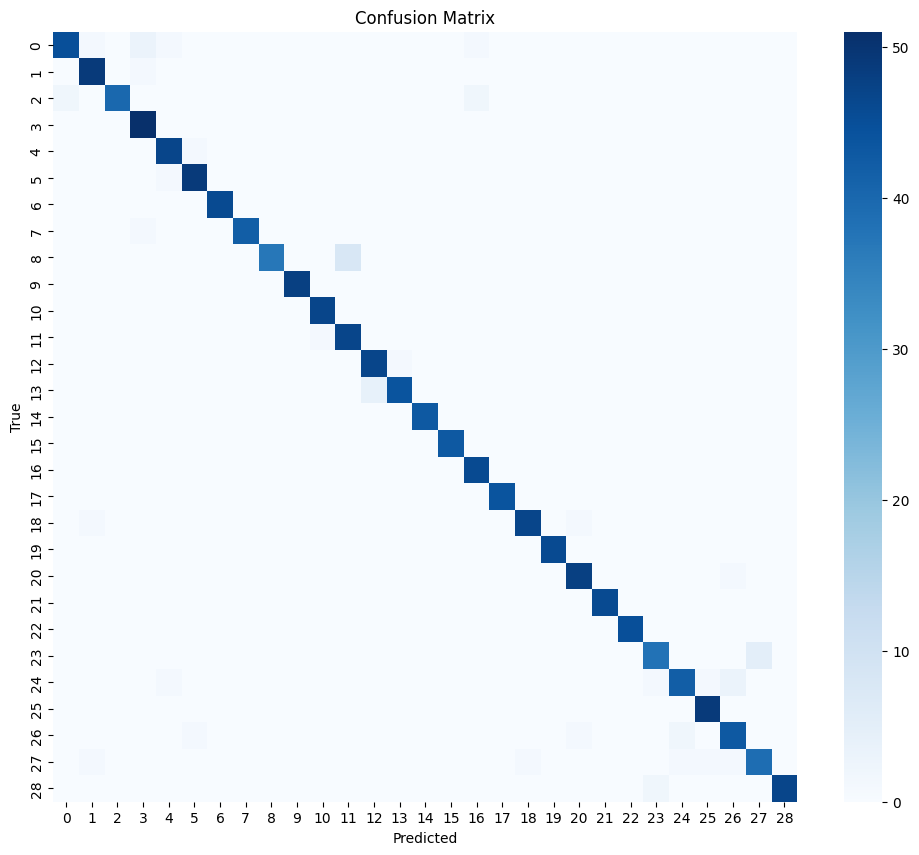

Classification Report:

                                     precision    recall  f1-score   support

                 Apple - Apple Scab       0.96      0.88      0.92        51
                  Apple - Black Rot       0.94      0.98      0.96        50
           Apple - Cedar Apple Rust       1.00      0.91      0.95        44
                    Apple - Healthy       0.91      1.00      0.95        51
       Bell Pepper - Bacterial Spot       0.94      0.98      0.96        48
              Bell Pepper - Healthy       0.96      0.98      0.97        50
                   Cherry - Healthy       1.00      1.00      1.00        46
            Cherry - Powdery Mildew       1.00      0.98      0.99        43
Corn (Maize) - Cercospora Leaf Spot       1.00      0.82      0.90        45
         Corn (Maize) - Common Rust       1.00      1.00      1.00        48
             Corn (Maize) - Healthy       0.98      1.00      0.99        47
Corn (Maize) - Northern Leaf Blight       0.85     

In [10]:
# 10. Confusion matrix + classification report
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

y_true = np.argmax(np.concatenate([y.numpy() for _, y in test_ds], axis=0), axis=1)
y_pred = np.argmax(model.predict(test_ds), axis=1)

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=False, cmap='Blues')
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Confusion Matrix')
plt.show()

print("Classification Report:\n")
print(classification_report(y_true, y_pred, target_names=class_names))

In [11]:
# 11. Save the model and download it to your computer
model.save('plant_effnetv2b0_final.keras')

try:
    from google.colab import files
    files.download('plant_effnetv2b0_final.keras')
except ImportError:
    pass
# Or save to Google Drive instead:
# from google.colab import drive
# drive.mount('/content/drive')
# model.save('/content/drive/MyDrive/plant_effnetv2b0_final.keras')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>